# Visualisation des données issues du web scraping

**Sujet.** Contenu textuel extrait d'une page d'iris.ma par `Scraper.py` : titres HTML, paragraphes et liens.  
**Problématique.** Comment la page répartit-elle ses éléments textuels, quels messages reviennent le plus souvent et où pointent les liens extraits ?

Ce notebook utilise `cleaned_data.csv` préparé dans `data_cleaning.ipynb`. Chaque ligne représente un élément HTML extrait, **pas un produit ni une vente**. Les graphiques décrivent cet instantané de la page.


## 1. Chargement et exploration des données


In [1]:
from collections import Counter
from pathlib import Path
import re
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 14,
                     "axes.labelsize": 11, "figure.autolayout": True})

chemin = Path("cleaned_data.csv")
if not chemin.exists():
    raise FileNotFoundError("Exécuter d'abord data_cleaning.ipynb pour créer cleaned_data.csv")

df = pd.read_csv(chemin, encoding="utf-8-sig")
colonnes = {"Element Type", "Content", "URL"}
if not colonnes.issubset(df.columns):
    raise ValueError(f"Colonnes attendues : {sorted(colonnes)} ; obtenues : {list(df.columns)}")

print("Dimensions :", df.shape)
display(df.head())


Dimensions : (362, 3)


,Element Type,Content,URL
0,H1,L’expert tech — du matériel informatique & électronique au Maroc,NaN
1,H2,Le Black Friday dure tout novembre sur,NaN
2,H2,Le poste de travail à prix Black Friday.,NaN
3,H2,Samsung Odyssey G3 24″ à prix Black Friday.,NaN
4,H2,Les PC MSI à prix Black Friday.,NaN


In [2]:
print("Types d'éléments :")
display(df["Element Type"].value_counts().rename_axis("Type").to_frame("Nombre"))
print("Contenus manquants :", df["Content"].isna().sum())
print("Types manquants :", df["Element Type"].isna().sum())
print("URL manquantes pour les liens :",
      df.loc[df["Element Type"].eq("Link"), "URL"].isna().sum())
print("URL vides pour les autres éléments : attendu, car ce ne sont pas des liens.")
print("Lignes identiques :", df.duplicated().sum())


Types d'éléments :


,Nombre
Type,
Paragraph,294
H2,30
H3,27
Link,10
H1,1


Contenus manquants : 0
Types manquants : 0
URL manquantes pour les liens : 0
URL vides pour les autres éléments : attendu, car ce ne sont pas des liens.
Lignes identiques : 124


**Préparation.** Aucun contenu vide n'a été observé dans l'instantané. Les valeurs manquantes de `URL` pour les titres et paragraphes sont normales. Les répétitions restent dans `df` : elles décrivent plusieurs apparitions d'un texte. Nous calculons les longueurs et les fréquences dans des colonnes auxiliaires, sans modifier le CSV source.


In [3]:
df["nb_caracteres"] = df["Content"].fillna("").str.len()
df["nb_mots"] = df["Content"].fillna("").str.split().str.len()

frequences = (df.groupby(["Element Type", "Content", "URL"], dropna=False)
                .size().reset_index(name="Occurrences"))
assert frequences["Occurrences"].sum() == len(df)
print("Éléments distincts :", len(frequences))
print("Occurrences totales :", frequences["Occurrences"].sum())


Éléments distincts : 238
Occurrences totales : 362


## 2. Graphique 1 — Composition de la page par type d'élément


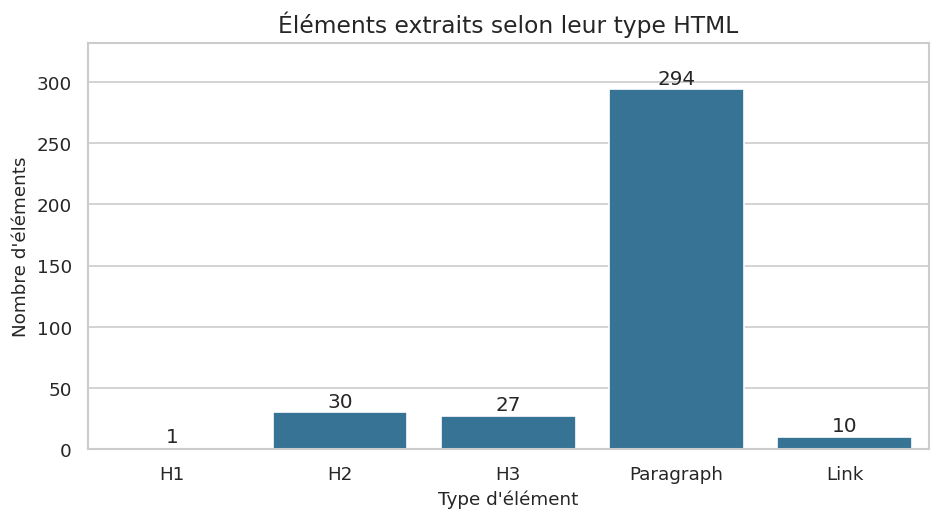

Interprétation : 294 paragraphes sur 362 éléments (81.2%). Le contenu extrait est surtout composé de paragraphes.


In [4]:
ordre = ["H1", "H2", "H3", "Paragraph", "Link"]
effectifs = df["Element Type"].value_counts().reindex(ordre, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=effectifs.index, y=effectifs.values, color="#2678a5", ax=ax)
for i, nombre in enumerate(effectifs):
    ax.text(i, nombre + max(effectifs) * 0.015, str(nombre), ha="center")
ax.set(ylim=(0, max(effectifs) * 1.13), title="Éléments extraits selon leur type HTML",
       xlabel="Type d'élément", ylabel="Nombre d'éléments")
plt.show()
print(f"Interprétation : {effectifs['Paragraph']} paragraphes sur {len(df)} éléments "
      f"({effectifs['Paragraph'] / len(df):.1%}). Le contenu extrait est surtout composé de paragraphes.")


Les effectifs décrivent les balises capturées par le script, pas l'importance visuelle réelle des sections ni le nombre de produits.


## 3. Graphique 2 — Distribution de la longueur des textes


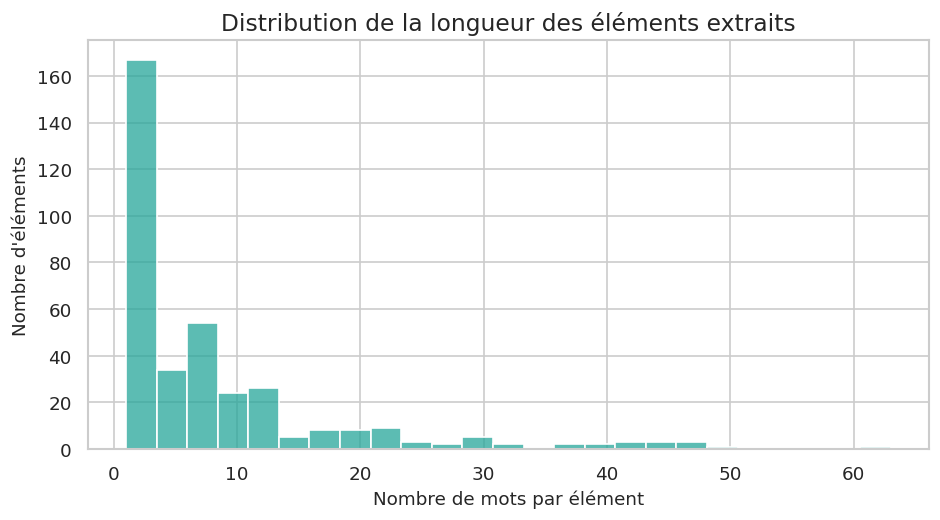

Interprétation : la médiane est de 5 mots. 201 éléments sur 362 comportent au plus 5 mots. Les textes courts sont fréquents dans cet extrait.


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df, x="nb_mots", bins=25, color="#25a69a", ax=ax)
ax.set(title="Distribution de la longueur des éléments extraits",
       xlabel="Nombre de mots par élément", ylabel="Nombre d'éléments")
plt.show()
print(f"Interprétation : la médiane est de {df['nb_mots'].median():.0f} mots. "
      f"{df['nb_mots'].le(5).sum()} éléments sur {len(df)} comportent au plus 5 mots. "
      "Les textes courts sont fréquents dans cet extrait.")


Un élément long constitue une seule observation, quelle que soit sa place sur la page.


## 4. Graphique 3 — Longueur des textes selon leur type


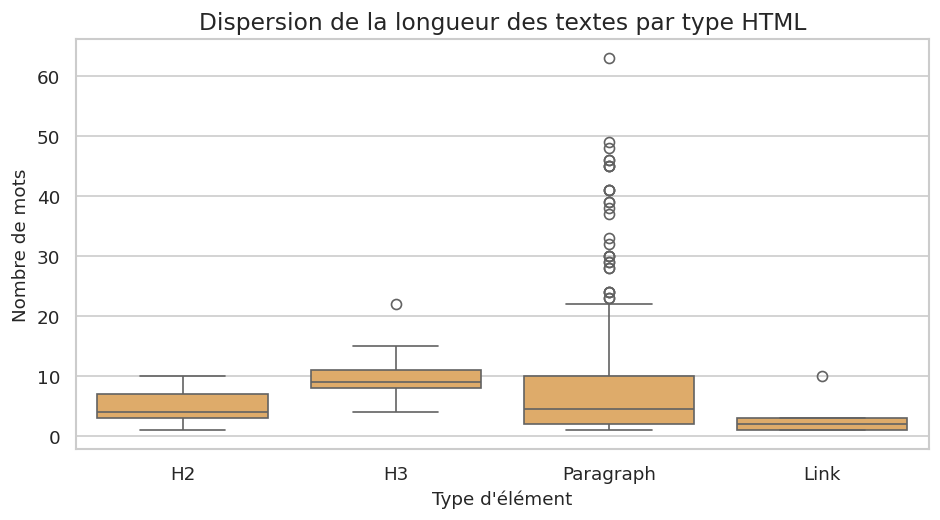

Interprétation : médiane H3 = 9 mots ; médiane Paragraph = 4 mots. Les points isolés correspondent à des textes plus longs que la majorité de leur groupe.


In [6]:
comparaison = df[df["Element Type"].isin(["H2", "H3", "Paragraph", "Link"])].copy()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=comparaison, x="Element Type", y="nb_mots",
            order=["H2", "H3", "Paragraph", "Link"], color="#f1ad57", ax=ax)
ax.set(title="Dispersion de la longueur des textes par type HTML",
       xlabel="Type d'élément", ylabel="Nombre de mots")
plt.show()
med_h3 = comparaison.loc[comparaison["Element Type"].eq("H3"), "nb_mots"].median()
med_p = comparaison.loc[comparaison["Element Type"].eq("Paragraph"), "nb_mots"].median()
print(f"Interprétation : médiane H3 = {med_h3:.0f} mots ; "
      f"médiane Paragraph = {med_p:.0f} mots. "
      "Les points isolés correspondent à des textes plus longs que la majorité de leur groupe.")


`H1` est exclu de cette comparaison car il n'y a qu'une seule observation : une boîte statistique ne serait pas informative.


## 5. Graphique 4 — Textes identiques les plus répétés


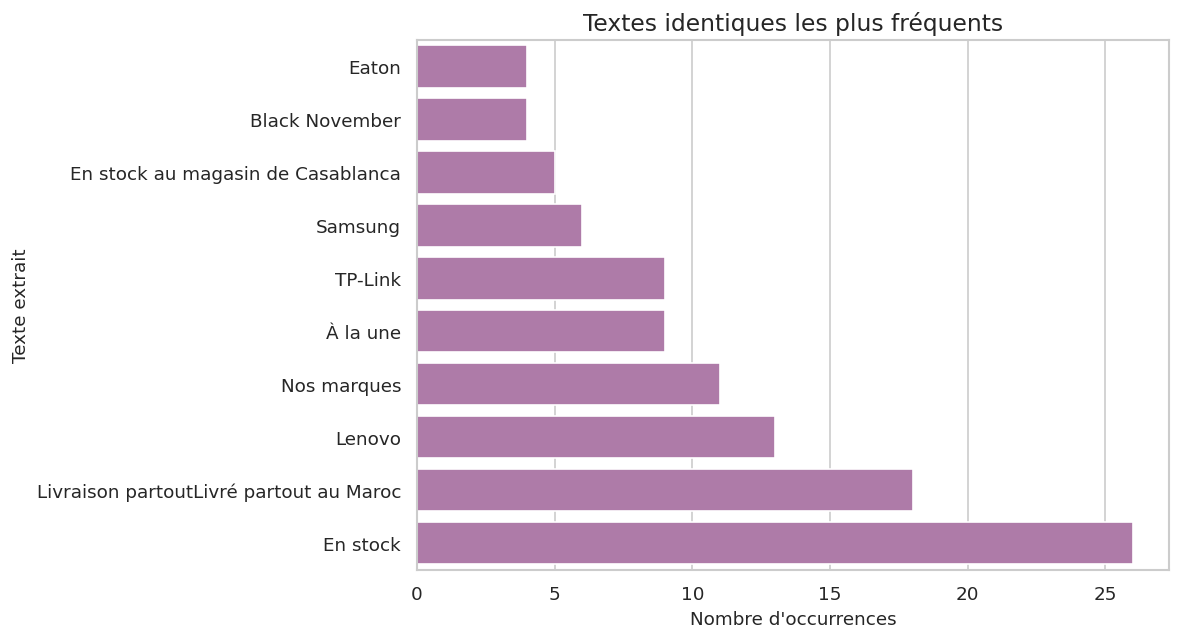

Interprétation : « En stock » apparaît 26 fois. Les répétitions comprennent des libellés d'interface et des mentions affichées dans plusieurs zones de la page.


In [7]:
top_repetitions = (frequences.loc[frequences["Occurrences"].gt(1)]
                   .nlargest(10, "Occurrences").sort_values("Occurrences"))
if top_repetitions.empty:
    print("Aucun texte répété dans ce jeu de données.")
else:
    etiquettes = top_repetitions["Content"].str.slice(0, 52)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    sns.barplot(x=top_repetitions["Occurrences"], y=etiquettes,
                color="#b772ae", ax=ax)
    ax.set(title="Textes identiques les plus fréquents",
           xlabel="Nombre d'occurrences", ylabel="Texte extrait")
    plt.show()
    premiere = top_repetitions.iloc[-1]
    print(f"Interprétation : « {premiere['Content']} » apparaît "
          f"{premiere['Occurrences']} fois. Les répétitions comprennent des libellés "
          "d'interface et des mentions affichées dans plusieurs zones de la page.")


Ces fréquences comptent des apparitions de chaînes de caractères ; elles ne mesurent ni les ventes, ni le stock, ni le nombre de produits uniques.


## 6. Graphique 5 — Mots fréquents dans les titres H3


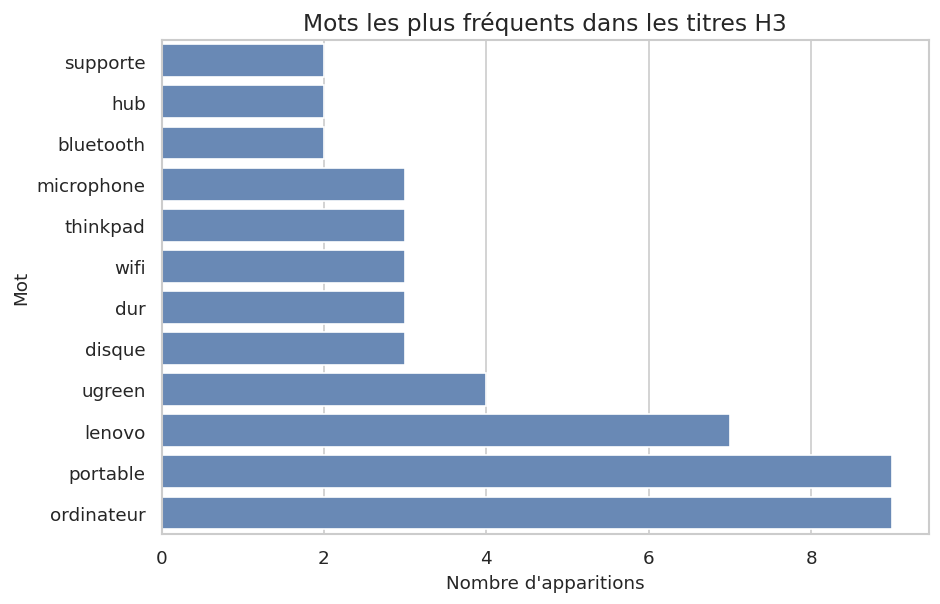

Interprétation : « ordinateur » est le mot retenu le plus fréquent (9 apparitions) parmi les 27 titres H3. Le filtre de mots vides est une règle d'analyse, non une classification officielle des produits.


In [8]:
stop = {"avec", "dans", "pour", "sans", "vers", "plus", "une", "des", "les",
        "sur", "aux", "son", "ses", "the", "and", "from", "that", "this",
        "usb", "gen", "type", "male", "femelle", "noir", "blanc", "cm", "mm"}
titres_h3 = df.loc[df["Element Type"].eq("H3"), "Content"].fillna("")
mots = Counter(mot.casefold() for titre in titres_h3
               for mot in re.findall(r"[^\W\d_]{3,}", titre, flags=re.UNICODE)
               if mot.casefold() not in stop)
top_mots = pd.DataFrame(mots.most_common(12), columns=["Mot", "Occurrences"])
if top_mots.empty:
    print("Aucun mot exploitable dans les titres H3.")
else:
    fig, ax = plt.subplots(figsize=(8, 5.2))
    sns.barplot(data=top_mots.iloc[::-1], x="Occurrences", y="Mot",
                color="#5c87c2", ax=ax)
    ax.set(title="Mots les plus fréquents dans les titres H3",
           xlabel="Nombre d'apparitions", ylabel="Mot")
    plt.show()
    print(f"Interprétation : « {top_mots.iloc[0]['Mot']} » est le mot retenu le "
          f"plus fréquent ({top_mots.iloc[0]['Occurrences']} apparitions) parmi "
          f"les {len(titres_h3)} titres H3. Le filtre de mots vides est une règle "
          "d'analyse, non une classification officielle des produits.")


Le découpage compte les mots visibles dans les titres, sans déduire automatiquement la marque ou la catégorie de chaque produit.


## 7. Graphique 6 — Domaines des liens extraits


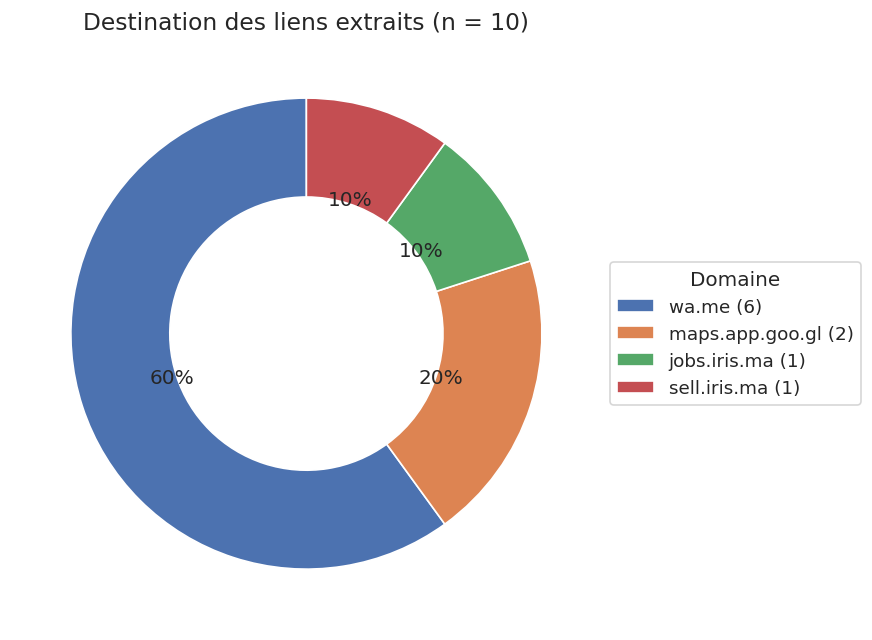

Interprétation : wa.me rassemble 6 liens sur 10. Le script ignore les liens relatifs et les liens sans texte : le graphique ne décrit donc pas tous les liens du site.


In [9]:
liens = df.loc[df["Element Type"].eq("Link") & df["URL"].notna(), "URL"]
domaines = liens.map(lambda url: urlparse(str(url)).netloc.lower()).value_counts()
if domaines.empty:
    print("Aucun lien avec URL dans le fichier.")
else:
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.pie(domaines.values, startangle=90, autopct="%1.0f%%",
           wedgeprops={"width": 0.42, "edgecolor": "white"})
    ax.legend([f"{nom} ({n})" for nom, n in domaines.items()],
              title="Domaine", loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(f"Destination des liens extraits (n = {len(liens)})")
    plt.show()
    print(f"Interprétation : {domaines.index[0]} rassemble {domaines.iloc[0]} "
          f"liens sur {len(liens)}. Le script ignore les liens relatifs et les liens "
          "sans texte : le graphique ne décrit donc pas tous les liens du site.")
